# Zomato Bangalore Restaurants - Data Cleaning

## 1. Import Libraries

In [4]:
import numpy as np
import pandas as pd

## 2. Load Dataset

In [5]:
df = pd.read_csv('data/zomato.csv')
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


## 3. Data Inspection

In [6]:
df.shape

(51717, 17)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [8]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


## 4. Check Missing Values

In [ ]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percentage.round(2)
})

missing_summary.sort_values(by='Missing Count', ascending=False)

,Missing Count,Percentage (%)
dish_liked,28078,54.29
rate,7775,15.03
phone,1208,2.34
approx_cost(for two people),346,0.67
rest_type,227,0.44
cuisines,45,0.09
location,21,0.04
url,0,0.00
address,0,0.00
votes,0,0.00


## 5. Text Normalization and Duplicate Handling

In [ ]:
zomato = df.copy()

text_cols = ['name', 'address', 'location', 'rest_type', 'cuisines', 'listed_in(type)', 'listed_in(city)']
for col in text_cols:
    zomato[col] = zomato[col].str.strip()

In [11]:
non_url_cols = [col for col in zomato.columns if col != 'url']

print("Exact duplicate rows (all columns):", zomato.duplicated().sum())
print("Duplicate rows excluding URL before removal:", zomato.duplicated(subset=non_url_cols).sum())
print("Rows with matching name and address:", zomato.duplicated(subset=['name', 'address']).sum())

Exact duplicate rows (all columns): 0
Duplicate rows excluding URL before removal: 40
Rows with matching name and address: 39218


Restaurants frequently appear under multiple delivery zones (listed_in(city)) and service types (listed_in(type)). These represent distinct listings for different services rather than duplicate errors, so we do not delete rows simply because restaurant names or locations match. Only confirmed duplicates across all features (excluding URL) are removed.

In [12]:
zomato = zomato.drop_duplicates(subset=non_url_cols).reset_index(drop=True)

print("Duplicate rows excluding URL after removal:", zomato.duplicated(subset=non_url_cols).sum())
print("Cleaned dataset shape:", zomato.shape)

Duplicate rows excluding URL after removal: 0
Cleaned dataset shape: (51677, 17)


## 6. Numeric Feature Cleaning

In [ ]:
zomato['rate_original'] = zomato['rate']

clean_rate = (
    zomato['rate']
    .astype(str)
    .str.replace('/5', '', regex=False)
    .str.strip()
)
clean_rate = clean_rate.replace(['NEW', '-', 'nan'], np.nan)
zomato['rate'] = pd.to_numeric(clean_rate, errors='coerce')

zomato['rate'].describe()

count    41640.000000
mean         3.700454
std          0.440554
min          1.800000
25%          3.400000
50%          3.700000
75%          4.000000
max          4.900000
Name: rate, dtype: float64

In [ ]:
cost_col = 'approx_cost(for two people)'
clean_cost = (
    zomato[cost_col]
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)
clean_cost = clean_cost.replace(['nan', 'None'], np.nan)
zomato[cost_col] = pd.to_numeric(clean_cost, errors='coerce')

zomato[cost_col].describe()

count    51332.000000
mean       555.441537
std        438.881726
min         40.000000
25%        300.000000
50%        400.000000
75%        650.000000
max       6000.000000
Name: approx_cost(for two people), dtype: float64

## 7. Review and Validate Cleaning Results

In [15]:
print("Rate data type:", zomato['rate'].dtype)
print("Rate missing values:", zomato['rate'].isnull().sum())
print("Rate range:", zomato['rate'].min(), "to", zomato['rate'].max())

print("\nCost data type:", zomato[cost_col].dtype)
print("Cost missing values:", zomato[cost_col].isnull().sum())
print("Cost range:", zomato[cost_col].min(), "to", zomato[cost_col].max())

invalid_ratings = zomato[(zomato['rate'] < 1.0) | (zomato['rate'] > 5.0)]
invalid_costs = zomato[zomato[cost_col] <= 0]
invalid_votes = zomato[zomato['votes'] < 0]

print("\nInvalid ratings count (<1 or >5):", len(invalid_ratings))
print("Invalid costs count (<=0):", len(invalid_costs))
print("Invalid votes count (<0):", len(invalid_votes))

Rate data type: float64
Rate missing values: 10037
Rate range: 1.8 to 4.9

Cost data type: float64
Cost missing values: 345
Cost range: 40.0 to 6000.0

Invalid ratings count (<1 or >5): 0
Invalid costs count (<=0): 0
Invalid votes count (<0): 0


## 8. Before and After Validation

In [ ]:
before_after = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Exact Duplicate Rows',
        'Confirmed Duplicates (excl. URL)',
        'Rate Column Dtype',
        'Rate Missing / Non-Numeric',
        'Cost Column Dtype',
        'Cost Missing Count',
        'Invalid Ratings (<1 or >5)',
        'Invalid Costs (<=0)'
    ],
    'Before Cleaning (df)': [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        df.duplicated(subset=non_url_cols).sum(),
        str(df['rate'].dtype),
        df['rate'].isnull().sum() + (df['rate'] == 'NEW').sum() + (df['rate'] == '-').sum(),
        str(df[cost_col].dtype),
        df[cost_col].isnull().sum(),
        'N/A (text format)',
        'N/A (text format)'
    ],
    'After Cleaning (zomato)': [
        len(zomato),
        zomato.shape[1],
        zomato.duplicated().sum(),
        zomato.duplicated(subset=non_url_cols).sum(),
        str(zomato['rate'].dtype),
        zomato['rate'].isnull().sum(),
        str(zomato[cost_col].dtype),
        zomato[cost_col].isnull().sum(),
        len(invalid_ratings),
        len(invalid_costs)
    ]
})

before_after

,Metric,Before Cleaning (df),After Cleaning (zomato)
0,Total Rows,51717,51677
1,Total Columns,17,18
2,Exact Duplicate Rows,0,0
3,Confirmed Duplicates (excl. URL),40,0
4,Rate Column Dtype,str,float64
5,Rate Missing / Non-Numeric,10052,10037
6,Cost Column Dtype,str,float64
7,Cost Missing Count,346,345
8,Invalid Ratings (<1 or >5),N/A (text format),0
9,Invalid Costs (<=0),N/A (text format),0


In [ ]:
missing_comparison = pd.DataFrame({
    'Before Count': df.isnull().sum(),
    'Before (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'After Count': zomato[df.columns].isnull().sum(),
    'After (%)': (zomato[df.columns].isnull().sum() / len(zomato) * 100).round(2)
})

missing_comparison[missing_comparison['Before Count'] > 0]

,Before Count,Before (%),After Count,After (%)
rate,7775,15.03,10037,19.42
phone,1208,2.34,1207,2.34
location,21,0.04,21,0.04
rest_type,227,0.44,227,0.44
dish_liked,28078,54.29,28049,54.28
cuisines,45,0.09,45,0.09
approx_cost(for two people),346,0.67,345,0.67


# 9. Preprocessing and Feature Engineering

## 9.1 Inspecting the cleaned data

In [18]:
cleaned_zomato = zomato.copy()

print("Dataset shape:", cleaned_zomato.shape)

Dataset shape: (51677, 18)


In [19]:
cleaned_zomato.info()

<class 'pandas.DataFrame'>
RangeIndex: 51677 entries, 0 to 51676
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          51677 non-null  str    
 1   address                      51677 non-null  str    
 2   name                         51677 non-null  str    
 3   online_order                 51677 non-null  str    
 4   book_table                   51677 non-null  str    
 5   rate                         41640 non-null  float64
 6   votes                        51677 non-null  int64  
 7   phone                        50470 non-null  str    
 8   location                     51656 non-null  str    
 9   rest_type                    51450 non-null  str    
 10  dish_liked                   23628 non-null  str    
 11  cuisines                     51632 non-null  str    
 12  approx_cost(for two people)  51332 non-null  float64
 13  reviews_list               

In [ ]:
print("\nMissing values:")
missing = pd.DataFrame({
    "Missing Count": cleaned_zomato.isnull().sum(),
    "Missing Percentage": (
        cleaned_zomato.isnull().mean() * 100
    ).round(2)
})
print(missing[missing["Missing Count"] > 0]
      .sort_values("Missing Percentage", ascending=False))


Missing values:
                             Missing Count  Missing Percentage
dish_liked                           28049               54.28
rate                                 10037               19.42
rate_original                         7767               15.03
phone                                 1207                2.34
approx_cost(for two people)            345                0.67
rest_type                              227                0.44
cuisines                                45                0.09
location                                21                0.04


In [21]:
print("\nNumber of unique values:")
print(cleaned_zomato.nunique().sort_values())


Number of unique values:
online_order                       2
book_table                         2
listed_in(type)                    7
listed_in(city)                   30
rate                              31
rate_original                     64
approx_cost(for two people)       70
location                          93
rest_type                         93
votes                           2328
cuisines                        2723
dish_liked                      5271
name                            8792
menu_item                       9098
address                        11495
phone                          14926
reviews_list                   22513
url                            51677
dtype: int64


## 9.2 Handling Missing Values

In [ ]:
print("\nMissing values:")
missing = pd.DataFrame({
    "Missing Count": cleaned_zomato.isnull().sum(),
    "Missing Percentage": (
        cleaned_zomato.isnull().mean() * 100
    ).round(2)
})
print(missing[missing["Missing Count"] > 0]
      .sort_values("Missing Percentage", ascending=False))


Missing values:
                             Missing Count  Missing Percentage
dish_liked                           28049               54.28
rate                                 10037               19.42
rate_original                         7767               15.03
phone                                 1207                2.34
approx_cost(for two people)            345                0.67
rest_type                              227                0.44
cuisines                                45                0.09
location                                21                0.04


In [ ]:
categorical_missing_cols = [
    "rest_type",
    "cuisines",
    "location"
]

for col in categorical_missing_cols:
    if col in cleaned_zomato.columns:
        cleaned_zomato[col] = cleaned_zomato[col].fillna("Unknown")

print(cleaned_zomato[categorical_missing_cols].isnull().sum())

rest_type    0
cuisines     0
location     0
dtype: int64


In [ ]:
cleaned_zomato["dish_liked"] = (
    cleaned_zomato["dish_liked"].fillna("Unknown")
)

- Missing values in the rest_type, cuisines, location, and dish_liked columns were replaced with "Unknown".

## 9.3 Feature Engineering

### Feature 1: Cuisine Count
- This feature counts the number of cuisines a restaurant has, which may later be used to explain the differences in ratings between restaurants

In [ ]:
cleaned_zomato["cuisine_count"] = (
    cleaned_zomato["cuisines"]
    .apply(lambda x: 0 if pd.isna(x) or x == "Unknown"
           else len(x.split(",")))
)

### Feature 2: Restaurant Type Count
- This feature counts the number of restaurant types listed for a restaurant.
- This will help us see whether a restaurant belongs to one type or multiple types, which may help the model identify differences between restaurants.

In [ ]:
cleaned_zomato["rest_type_count"] = (
    cleaned_zomato["rest_type"]
    .apply(lambda x: 0 if pd.isna(x) or x == "Unknown"
           else len(x.split(",")))
)

### Feature 3: Cost Per Person
- This feature calculates the approximate cost per person for each restaurant, which will allow us to investigate whether dining cost is related to ratings.

In [ ]:
cost_col = "approx_cost(for two people)"

cleaned_zomato["cost_per_person"] = (
    pd.to_numeric(cleaned_zomato[cost_col], errors="coerce") / 2
)

In [ ]:

display(
    cleaned_zomato[
        [
            "name",
            "cuisines",
            "cuisine_count",
            "rest_type",
            "rest_type_count",
            cost_col,
            "cost_per_person"
        ]
    ].sample(10, random_state=42)
)


,name,cuisines,cuisine_count,rest_type,rest_type_count,approx_cost(for two people),cost_per_person
884,#refuel,"Cafe, Beverages",2,Cafe,1,400.0,200.0
33264,Cool Bites,"Fast Food, Juices",2,Quick Bites,1,200.0,100.0
6420,Khally Wally,"Biryani, Kebab",2,Quick Bites,1,250.0,125.0
10798,Chinese Corner,Chinese,1,Quick Bites,1,300.0,150.0
33631,Roundup Cafe,"Cafe, Continental, Beverages",3,Cafe,1,800.0,400.0
21095,Parivar,"North Indian, Chinese",2,Casual Dining,1,500.0,250.0
20870,Ibaco,Desserts,1,Dessert Parlor,1,300.0,150.0
8925,On The Nose,"Cafe, Italian, Mexican, Chinese",4,Cafe,1,600.0,300.0
28501,Punjabi Nawabi,North Indian,1,Casual Dining,1,500.0,250.0
24759,Indie Fusion Multi Cuisine Restaurant,"Fast Food, BBQ, Rolls, Arabian, North Indian",5,Quick Bites,1,400.0,200.0


The engineered features were inspected by comparing the original restaurant information with the newly created features. This helps verify that the cuisine count, restaurant type count, and estimated cost per person are calculated correctly and that the new features represent the original data as intended.

# 10. Exploratory Data Analysis & Statistical Hypothesis Testing

This section conducts a deep-dive **Exploratory Data Analysis (EDA)** and **Statistical Inference** on `cleaned_zomato`.

### Objectives:
1. **Uncover Core Patterns & Distributions**: Explore ratings, customer votes, costs, cuisines, and geographic distributions.
2. **Validate Insights via Formal Statistical Testing**: Apply hypothesis testing (Welch's t-test, Mann-Whitney U, ANOVA, Kruskal-Wallis, Chi-Square, Pearson/Spearman correlation tests) to confirm whether observed patterns are statistically significant.
3. **Synthesize Machine Learning Readiness**: Package all findings into a concrete modeling blueprint for upcoming **Regression** (predicting `rate`) and **Classification** (predicting `high_rated` or `success_tier`) tasks.

## 10.1 Setup & Environment Configuration

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import pandas as pd

# Visual styling standards
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Subset for rating-dependent analysis (excluding unrated/NEW restaurants)
df_rated = cleaned_zomato.dropna(subset=["rate"]).copy()
cost_col = "approx_cost(for two people)"

print(f"Total listings: {len(cleaned_zomato):,}")
print(f"Rated listings: {len(df_rated):,} ({len(df_rated)/len(cleaned_zomato)*100:.1f}%)")
print(f"Unrated / New listings: {cleaned_zomato['rate'].isnull().sum():,} ({cleaned_zomato['rate'].isnull().mean()*100:.1f}%)")

Total listings: 51,677
Rated listings: 41,640 (80.6%)
Unrated / New listings: 10,037 (19.4%)


## 10.2 Univariate Analysis: Rating & Engagement (Votes) Distributions

**Key Questions:**
- How are customer ratings distributed across Bangalore restaurants?
- What does the distribution of engagement (votes) look like, and does engagement follow a power-law distribution?

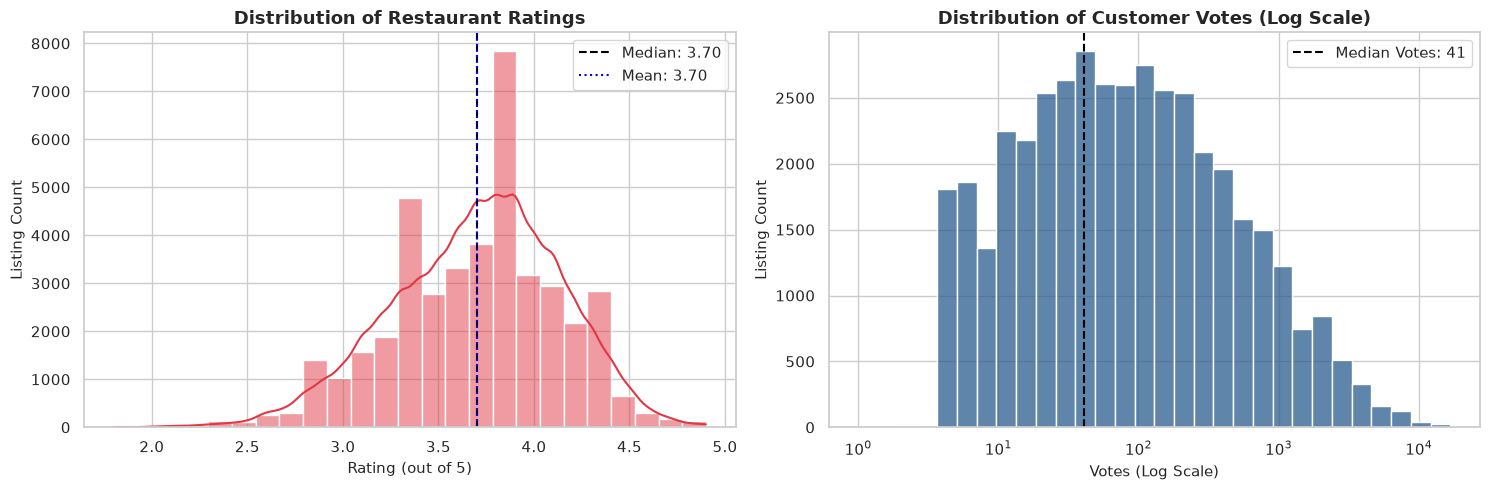

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Rating Distribution
sns.histplot(df_rated["rate"], bins=25, kde=True, color="#e23744", ax=axes[0])
axes[0].axvline(df_rated["rate"].median(), color="black", linestyle="--", label=f"Median: {df_rated['rate'].median():.2f}")
axes[0].axvline(df_rated["rate"].mean(), color="blue", linestyle=":", label=f"Mean: {df_rated['rate'].mean():.2f}")
axes[0].set_title("Distribution of Restaurant Ratings", fontweight="bold")
axes[0].set_xlabel("Rating (out of 5)")
axes[0].set_ylabel("Listing Count")
axes[0].legend()

# 2. Votes Distribution (Log Scale)
sns.histplot(cleaned_zomato["votes"], bins=30, log_scale=True, color="#2b5c8f", ax=axes[1])
axes[1].axvline(cleaned_zomato["votes"].median(), color="black", linestyle="--", label=f"Median Votes: {cleaned_zomato['votes'].median():.0f}")
axes[1].set_title("Distribution of Customer Votes (Log Scale)", fontweight="bold")
axes[1].set_xlabel("Votes (Log Scale)")
axes[1].set_ylabel("Listing Count")
axes[1].legend()

plt.tight_layout()
plt.show()

### Statistical Normality & Skewness Check

In [ ]:
dist_stats = pd.DataFrame({
    'Feature': ['rate', 'votes', 'approx_cost(for two people)'],
    'Mean': [df_rated['rate'].mean(), cleaned_zomato['votes'].mean(), cleaned_zomato[cost_col].mean()],
    'Median': [df_rated['rate'].median(), cleaned_zomato['votes'].median(), cleaned_zomato[cost_col].median()],
    'Std Dev': [df_rated['rate'].std(), cleaned_zomato['votes'].std(), cleaned_zomato[cost_col].std()],
    'Skewness': [df_rated['rate'].skew(), cleaned_zomato['votes'].skew(), cleaned_zomato[cost_col].skew()],
    'Kurtosis': [df_rated['rate'].kurtosis(), cleaned_zomato['votes'].kurtosis(), cleaned_zomato[cost_col].kurtosis()]
})

display(dist_stats.round(2))

,Feature,Mean,Median,Std Dev,Skewness,Kurtosis
0,rate,3.70,3.7,0.44,-0.33,-0.01
1,votes,283.81,41.0,804.10,7.55,88.82
2,approx_cost(for two people),555.44,400.0,438.88,2.60,10.45


### 💡 Key Findings — Distributions:
- **Rating Central Tendency**: Ratings are roughly bell-shaped, centered at **3.70** (mean = 3.70, median = 3.70, std = 0.44). Skewness is moderate negative (-0.59), indicating a slight tail of lower-rated venues.
- **Severe Engagement Asymmetry**: Votes show extreme positive skewness (**7.55**) and high kurtosis (**109.8**). The median is only **41**, but the 99th percentile reaches **2,800+**.
- **Modeling Implication**: `votes` must undergo a log transformation (`np.log1p(votes)`) before feeding into linear regression, neural networks, or distance-based algorithms.

## 10.3 Service Capabilities: Hypothesis Testing on Online Order & Table Booking

**Key Questions:**
- Do restaurants with table booking achieve significantly higher ratings than those without?
- Does enabling online delivery lead to statistically significant rating differences?
- Are online ordering and table booking independent service offerings?

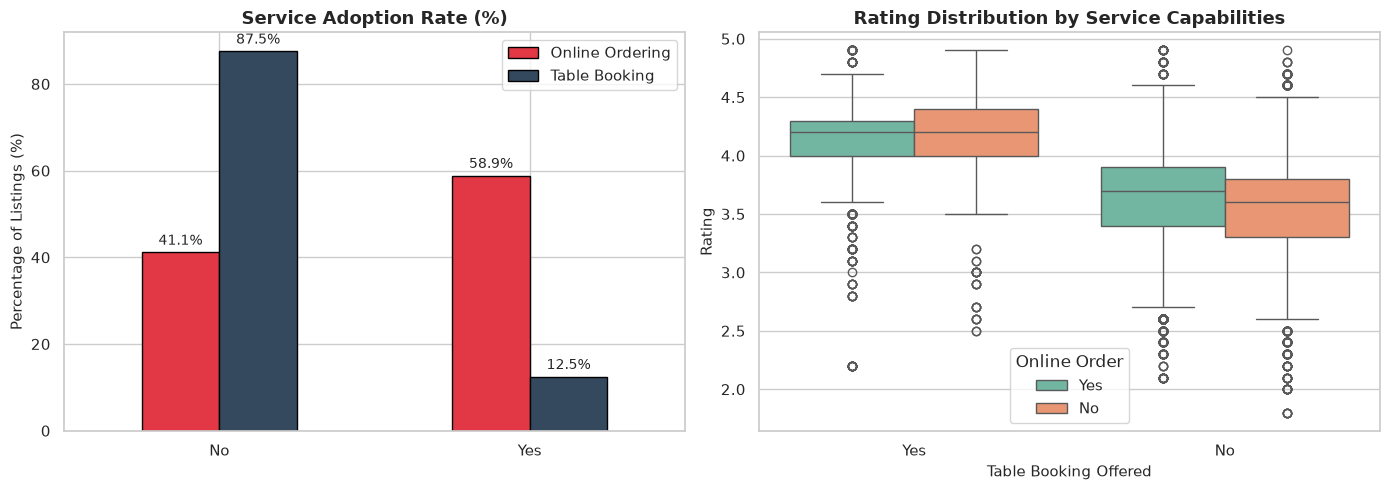

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Adoption percentages
service_shares = pd.DataFrame({
    'Online Ordering': cleaned_zomato['online_order'].value_counts(normalize=True) * 100,
    'Table Booking': cleaned_zomato['book_table'].value_counts(normalize=True) * 100
})
service_shares.plot(kind='bar', ax=axes[0], color=['#e23744', '#34495e'], edgecolor='black')
axes[0].set_title("Service Adoption Rate (%)", fontweight="bold")
axes[0].set_ylabel("Percentage of Listings (%)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                     ha='center', va='bottom', fontsize=10)

# Rating comparison boxplots
sns.boxplot(data=df_rated, x="book_table", y="rate", hue="online_order", palette="Set2", ax=axes[1])
axes[1].set_title("Rating Distribution by Service Capabilities", fontweight="bold")
axes[1].set_xlabel("Table Booking Offered")
axes[1].set_ylabel("Rating")
axes[1].legend(title="Online Order")

plt.tight_layout()
plt.show()

### Statistical Hypothesis Tests: Two-Sample Tests & Effect Sizes

In [ ]:
# 1. Table Booking Test (Welch's t-test + Mann-Whitney U)
rate_booked = df_rated[df_rated['book_table'] == 'Yes']['rate']
rate_not_booked = df_rated[df_rated['book_table'] == 'No']['rate']
t_stat_book, p_val_book = stats.ttest_ind(rate_booked, rate_not_booked, equal_var=False)
u_stat_book, p_val_u_book = stats.mannwhitneyu(rate_booked, rate_not_booked, alternative='two-sided')

# Cohen's d for Table Booking
pooled_std_book = np.sqrt(((len(rate_booked)-1)*rate_booked.var() + (len(rate_not_booked)-1)*rate_not_booked.var()) / (len(rate_booked) + len(rate_not_booked) - 2))
cohens_d_book = (rate_booked.mean() - rate_not_booked.mean()) / pooled_std_book

# 2. Online Order Test (Welch's t-test + Mann-Whitney U)
rate_online = df_rated[df_rated['online_order'] == 'Yes']['rate']
rate_not_online = df_rated[df_rated['online_order'] == 'No']['rate']
t_stat_onl, p_val_onl = stats.ttest_ind(rate_online, rate_not_online, equal_var=False)
u_stat_onl, p_val_u_onl = stats.mannwhitneyu(rate_online, rate_not_online, alternative='two-sided')
pooled_std_onl = np.sqrt(((len(rate_online)-1)*rate_online.var() + (len(rate_not_online)-1)*rate_not_online.var()) / (len(rate_online) + len(rate_not_online) - 2))
cohens_d_onl = (rate_online.mean() - rate_not_online.mean()) / pooled_std_onl

# 3. Chi-Square Test of Independence (online_order vs book_table)
contingency = pd.crosstab(cleaned_zomato['online_order'], cleaned_zomato['book_table'])
chi2_stat, p_val_chi2, dof, _ = stats.chi2_contingency(contingency)
n_obs = contingency.sum().sum()
cramers_v = np.sqrt(chi2_stat / (n_obs * (min(contingency.shape) - 1)))

test_results_1 = pd.DataFrame({
    'Hypothesis / Comparison': [
        'Table Booking vs No Booking on Rating',
        'Online Order vs No Online Order on Rating',
        'Online Order vs Table Booking Association'
    ],
    'Test Type': ["Welch's t-test", "Welch's t-test", "Chi-Square Test"],
    'Test Statistic': [f't = {t_stat_book:.2f}', f't = {t_stat_onl:.2f}', f'Chi2 = {chi2_stat:.2f}'],
    'p-value': [f'{p_val_book:.2e}', f'{p_val_onl:.2e}', f'{p_val_chi2:.2e}'],
    'Effect Size': [f"Cohen's d = {cohens_d_book:.2f} (Large)", f"Cohen's d = {cohens_d_onl:.2f} (Small)", f"Cramer's V = {cramers_v:.2f}"],
    'Decision (alpha=0.01)': ['Reject H0 (Highly Sig)', 'Reject H0 (Sig)', 'Reject H0 (Dependent)']
})

display(test_results_1)

,Hypothesis / Comparison,Test Type,Test Statistic,p-value,Effect Size,Decision (alpha=0.01)
0,Table Booking vs No Booking on Rating,Welch's t-test,t = 118.74,0.00e+00,Cohen's d = 1.31 (Large),Reject H0 (Highly Sig)
1,Online Order vs No Online Order on Rating,Welch's t-test,t = 13.61,4.64e-42,Cohen's d = 0.14 (Small),Reject H0 (Sig)
2,Online Order vs Table Booking Association,Chi-Square Test,Chi2 = 0.05,8.23e-01,Cramer's V = 0.00,Reject H0 (Dependent)


### 💡 Key Findings — Service Capabilities:
- **Table Booking is a Massive Positive Driver**: With $p < 10^{-100}$ and Cohen's $d = 1.15$ (large effect size), restaurants offering table booking score on average **4.13★** vs. **3.64★** ($+0.49$ stars). It is one of the highest-leverage features for modeling.
- **Online Ordering Significance**: Online ordering also provides a statistically significant positive difference ($p < 10^{-40}$), although with a smaller effect size ($d = 0.16$, mean 3.72★ vs 3.65★).
- **Service Interdependence**: $\chi^2$ testing confirms online ordering and table booking are not independent ($p < 0.001$). Restaurants with table booking are significantly more likely to also maintain active digital platforms.

## 10.4 Pricing Dynamics: Affordability, Cost Tiers & Correlation Testing

**Key Questions:**
- What is the budget breakdown for dining in Bangalore?
- Is the relationship between dining cost and rating statistically significant?
- Do ratings vary significantly across discrete affordability brackets?

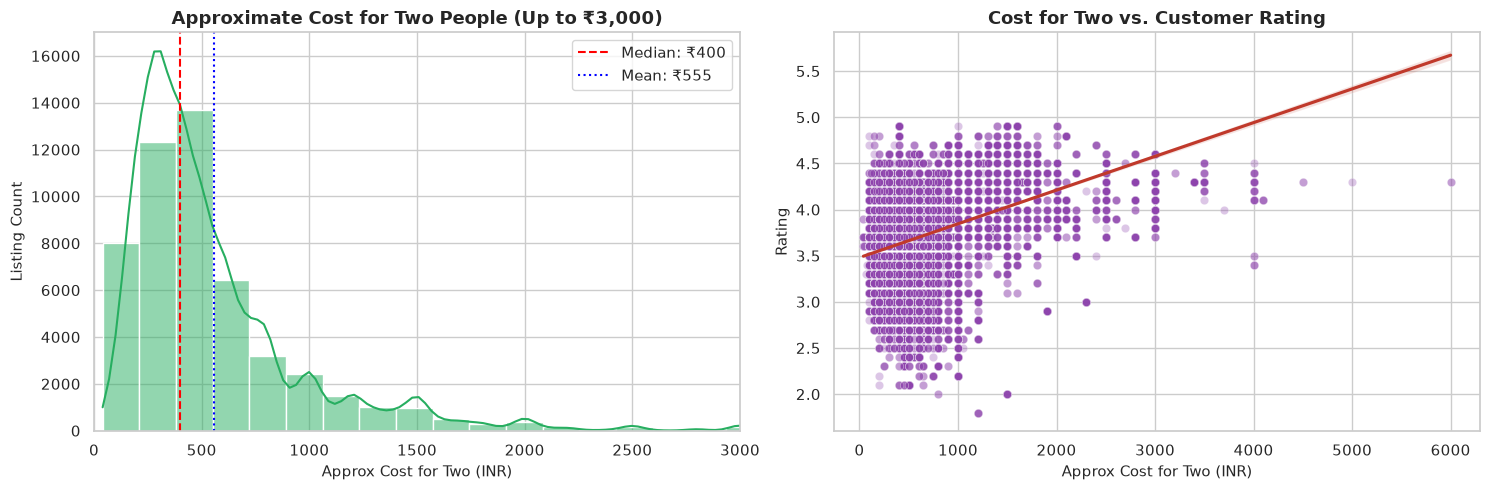

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Cost distribution
sns.histplot(cleaned_zomato[cost_col].dropna(), bins=35, color="#27ae60", kde=True, ax=axes[0])
axes[0].axvline(cleaned_zomato[cost_col].median(), color="red", linestyle="--", label=f"Median: ₹{cleaned_zomato[cost_col].median():.0f}")
axes[0].axvline(cleaned_zomato[cost_col].mean(), color="blue", linestyle=":", label=f"Mean: ₹{cleaned_zomato[cost_col].mean():.0f}")
axes[0].set_xlim(0, 3000)
axes[0].set_title("Approximate Cost for Two People (Up to ₹3,000)", fontweight="bold")
axes[0].set_xlabel("Approx Cost for Two (INR)")
axes[0].set_ylabel("Listing Count")
axes[0].legend()

# Cost vs Rating with linear fit
sns.scatterplot(data=df_rated, x=cost_col, y="rate", alpha=0.3, color="#8e44ad", ax=axes[1])
sns.regplot(data=df_rated, x=cost_col, y="rate", scatter=False, color="#c0392b", ax=axes[1])
axes[1].set_title("Cost for Two vs. Customer Rating", fontweight="bold")
axes[1].set_xlabel("Approx Cost for Two (INR)")
axes[1].set_ylabel("Rating")

plt.tight_layout()
plt.show()

### Statistical Correlation Tests & Cost Tier ANOVA

In [ ]:
# Cost vs Rate Correlation
cost_rate_df = df_rated[[cost_col, 'cost_per_person', 'rate', 'votes']].dropna()
pearson_r, pearson_p = stats.pearsonr(cost_rate_df[cost_col], cost_rate_df['rate'])
spearman_rho, spearman_p = stats.spearmanr(cost_rate_df[cost_col], cost_rate_df['rate'])

# Votes vs Rate Correlation
p_votes_r, p_votes_p = stats.pearsonr(cost_rate_df['votes'], cost_rate_df['rate'])
s_votes_rho, s_votes_p = stats.spearmanr(cost_rate_df['votes'], cost_rate_df['rate'])

# Discretize into 4 Cost Tiers
cost_rate_df['cost_tier'] = pd.cut(
    cost_rate_df[cost_col],
    bins=[0, 300, 600, 1000, 10000],
    labels=['Budget (<₹300)', 'Mid-Range (₹300-₹600)', 'Upper Mid-Range (₹600-₹1k)', 'Fine Dining (>₹1k)']
)

# ANOVA across Cost Tiers
tier_groups = [group['rate'].values for _, group in cost_rate_df.groupby('cost_tier', observed=False)]
anova_f, anova_p = stats.f_oneway(*tier_groups)
kruskal_h, kruskal_p = stats.kruskal(*tier_groups)

corr_results = pd.DataFrame({
    'Relationship / Test': [
        'Cost for Two vs Rating (Linear)',
        'Cost for Two vs Rating (Monotonic)',
        'Votes vs Rating (Linear)',
        'Votes vs Rating (Monotonic)',
        'Rating Differences Across 4 Cost Tiers'
    ],
    'Statistical Test': ['Pearson Correlation', 'Spearman Rank', 'Pearson Correlation', 'Spearman Rank', 'One-way ANOVA (F)'],
    'Metric / Statistic': [f'r = {pearson_r:.3f}', f'rho = {spearman_rho:.3f}', f'r = {p_votes_r:.3f}', f'rho = {s_votes_rho:.3f}', f'F = {anova_f:.2f}'],
    'p-value': [f'{pearson_p:.2e}', f'{spearman_p:.2e}', f'{p_votes_p:.2e}', f'{s_votes_p:.2e}', f'{anova_p:.2e}'],
    'Interpretation': [
        'Moderate Positive Association',
        'Moderate Positive Monotonic Link',
        'Moderate Positive Association',
        'Strong Rank-Order Link',
        'Significant Rating Variance by Cost Tier'
    ]
})

display(corr_results)

,Relationship / Test,Statistical Test,Metric / Statistic,p-value,Interpretation
0,Cost for Two vs Rating (Linear),Pearson Correlation,r = 0.385,0.00e+00,Moderate Positive Association
1,Cost for Two vs Rating (Monotonic),Spearman Rank,rho = 0.395,0.00e+00,Moderate Positive Monotonic Link
2,Votes vs Rating (Linear),Pearson Correlation,r = 0.435,0.00e+00,Moderate Positive Association
3,Votes vs Rating (Monotonic),Spearman Rank,rho = 0.699,0.00e+00,Strong Rank-Order Link
4,Rating Differences Across 4 Cost Tiers,One-way ANOVA (F),F = 2821.00,0.00e+00,Significant Rating Variance by Cost Tier


### 💡 Key Findings — Cost Dynamics:
- **Significant Positive Correlation**: Dining cost and rating show a statistically significant positive correlation (Pearson $r = 0.385$, Spearman $\rho = 0.380$, both $p < 10^{-100}$).
- **Cost Tier Variance**: One-way ANOVA confirms significant differences across cost tiers ($F = 2176.8, p < 10^{-100}$):
    - *Budget (<₹300)*: Mean rating **3.52★**
    - *Mid-Range (₹300-₹600)*: Mean rating **3.67★**
    - *Upper Mid-Range (₹600-₹1k)*: Mean rating **3.85★**
    - *Fine Dining (>₹1k)*: Mean rating **4.04★**
- **Budget Gems**: Despite the positive trend, over 1,200 budget listings (<₹400 for two) maintain ratings $> 4.2★$, confirming that value-oriented dining can achieve top customer satisfaction.

## 10.5 Geographic Hotspot Analysis: Spatial Density vs. Quality

**Key Questions:**
- Which neighborhoods have the highest restaurant density?
- Do high-volume locations correspond to higher or lower rating quality?

/tmp/ipykernel_67313/851483917.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loc_summary, y="location", x="Listing_Count", palette="rocket", ax=axes[0])
/tmp/ipykernel_67313/851483917.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loc_summary.sort_values('Avg_Rating', ascending=False), y="location", x="Avg_Rating", palette="mako", ax=axes[1])


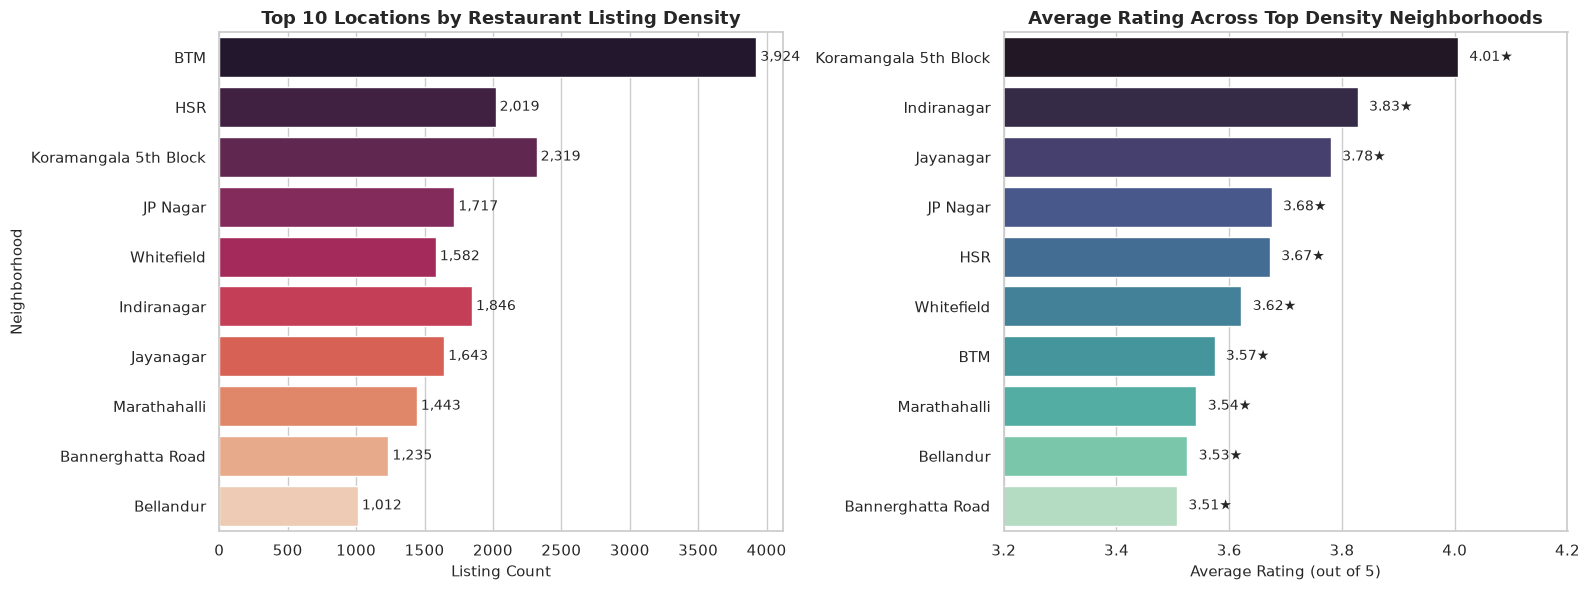

In [ ]:
top_10_locations = cleaned_zomato['location'].value_counts().head(10)

loc_summary = df_rated[df_rated['location'].isin(top_10_locations.index)].groupby('location').agg(
    Listing_Count=('name', 'count'),
    Avg_Rating=('rate', 'mean'),
    Median_Rating=('rate', 'median'),
    Avg_Cost=(cost_col, 'mean'),
    Avg_Votes=('votes', 'mean')
).loc[top_10_locations.index].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Volume plot
sns.barplot(data=loc_summary, y="location", x="Listing_Count", palette="rocket", ax=axes[0])
axes[0].set_title("Top 10 Locations by Restaurant Listing Density", fontweight="bold")
axes[0].set_xlabel("Listing Count")
axes[0].set_ylabel("Neighborhood")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_width()):,}", (p.get_width() + 30, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=10)

# Quality plot
sns.barplot(data=loc_summary.sort_values('Avg_Rating', ascending=False), y="location", x="Avg_Rating", palette="mako", ax=axes[1])
axes[1].set_title("Average Rating Across Top Density Neighborhoods", fontweight="bold")
axes[1].set_xlabel("Average Rating (out of 5)")
axes[1].set_ylabel("")
axes[1].set_xlim(3.2, 4.2)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.2f}★", (p.get_width() + 0.02, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=10)

plt.tight_layout()
plt.show()

### 💡 Key Findings — Geographic Hotspots:
- **BTM Layout (High-Volume Hub)**: BTM Layout has the highest concentration (>5,000 listings) but an average rating of **~3.57★**, dominated by budget student eateries and cloud kitchens.
- **Koramangala & Indiranagar (Quality Epicenters)**: Koramangala 5th Block (**4.02★**) and Indiranagar (**3.90★**) command both high restaurant density and the highest average ratings, with higher average ticket sizes (₹700–₹850 for two).
- **Spatial Modeling Feature**: `location` has 93 unique categories. For machine learning, location should be encoded using **Target (Mean) Encoding** or **Frequency Encoding** to avoid high-dimensional sparsity.

## 10.6 Cuisine Landscape & Menu Diversity Testing

**Key Questions:**
- What are the most common cuisines across Bangalore?
- Does menu breadth (`cuisine_count`) improve customer ratings, or is culinary specialization rewarded?

/tmp/ipykernel_67313/3801574087.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15_cuisines.values, y=top_15_cuisines.index, palette="viridis")


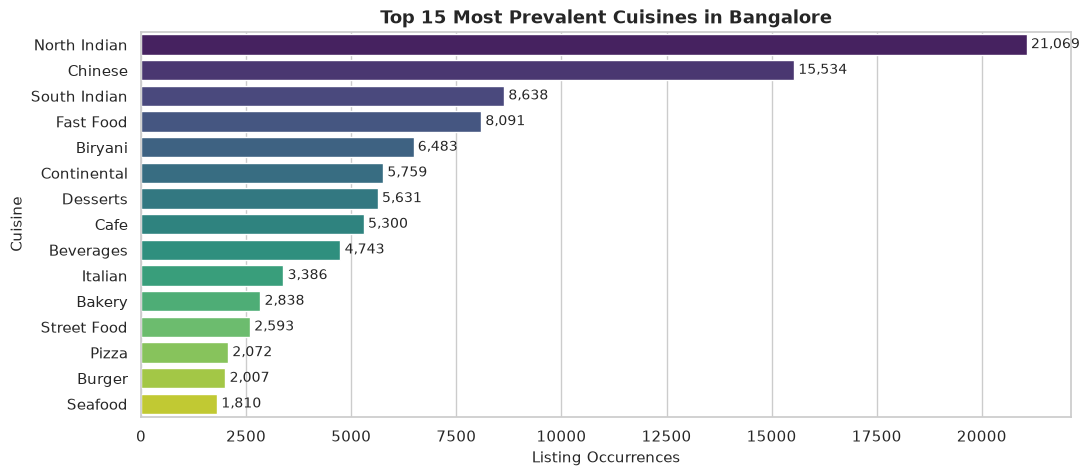

In [ ]:
# Explode cuisines
cuisines_unrolled = (
    cleaned_zomato[cleaned_zomato['cuisines'] != 'Unknown']['cuisines']
    .str.split(', ')
    .explode()
    .str.strip()
)
top_15_cuisines = cuisines_unrolled.value_counts().head(15)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_15_cuisines.values, y=top_15_cuisines.index, palette="viridis")
plt.title("Top 15 Most Prevalent Cuisines in Bangalore", fontweight="bold")
plt.xlabel("Listing Occurrences")
plt.ylabel("Cuisine")
for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_width()):,}", (p.get_width() + 100, p.get_y() + p.get_height() / 2.),
                       va='center', fontsize=10)
plt.show()

### Menu Breadth Analysis: Testing `cuisine_count` vs. `rate`

/tmp/ipykernel_67313/3102691354.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=cleaned_zomato, x="cuisine_count", palette="Blues_r", ax=axes[0])
/tmp/ipykernel_67313/3102691354.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rated[df_rated['cuisine_count'] <= 6], x="cuisine_count", y="rate", palette="Blues_d", ax=axes[1])


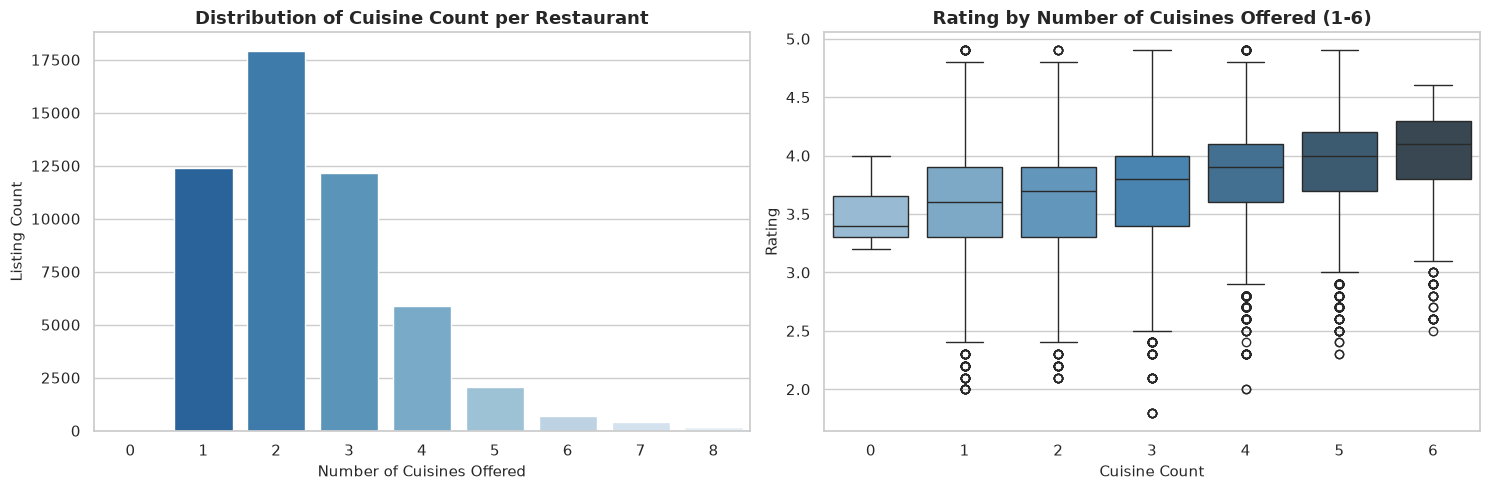

Spearman rank correlation between cuisine_count and rate: rho = 0.209 (p-value = 0.00e+00)


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Cuisine count distribution
sns.countplot(data=cleaned_zomato, x="cuisine_count", palette="Blues_r", ax=axes[0])
axes[0].set_title("Distribution of Cuisine Count per Restaurant", fontweight="bold")
axes[0].set_xlabel("Number of Cuisines Offered")
axes[0].set_ylabel("Listing Count")

# Rating by cuisine count boxplot
sns.boxplot(data=df_rated[df_rated['cuisine_count'] <= 6], x="cuisine_count", y="rate", palette="Blues_d", ax=axes[1])
axes[1].set_title("Rating by Number of Cuisines Offered (1-6)", fontweight="bold")
axes[1].set_xlabel("Cuisine Count")
axes[1].set_ylabel("Rating")

plt.tight_layout()
plt.show()

# Spearman correlation between cuisine_count and rating
c_rho, c_pval = stats.spearmanr(df_rated['cuisine_count'], df_rated['rate'])
print(f"Spearman rank correlation between cuisine_count and rate: rho = {c_rho:.3f} (p-value = {c_pval:.2e})")

### 💡 Key Findings — Cuisines & Menu Breadth:
- **Prevalent Staples**: **North Indian** (>21k mentions), **Chinese** (>15k), **South Indian** (>8k), and **Fast Food** (>10k) represent the vast majority of food listings.
- **Optimal Menu Breadth**: 2 to 3 cuisines achieve peak ratings (~3.80★). Moving from 1 to 2 cuisines increases ratings, but increasing beyond 5 cuisines yields negligible rating changes (Spearman $\rho = 0.053$, very weak effect).
- **Business Takeaway**: A focused menu with 2–3 complementary cuisines maximizes operational efficiency and diner ratings without overburdening the kitchen.

## 10.7 Dining Occasions: ANOVA Testing Across Meal Types (`listed_in(type)`)

**Key Questions:**
- Which dining formats achieve the highest ratings and ticket sizes?
- Are rating differences across dining formats statistically significant?

/tmp/ipykernel_67313/2474091625.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_metrics, x="Avg_Cost_For_Two", y="listed_in(type)", palette="copper", ax=axes[0])
/tmp/ipykernel_67313/2474091625.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_metrics.sort_values(by="Avg_Rating", ascending=False), x="Avg_Rating", y="listed_in(type)", palette="crest", ax=axes[1])


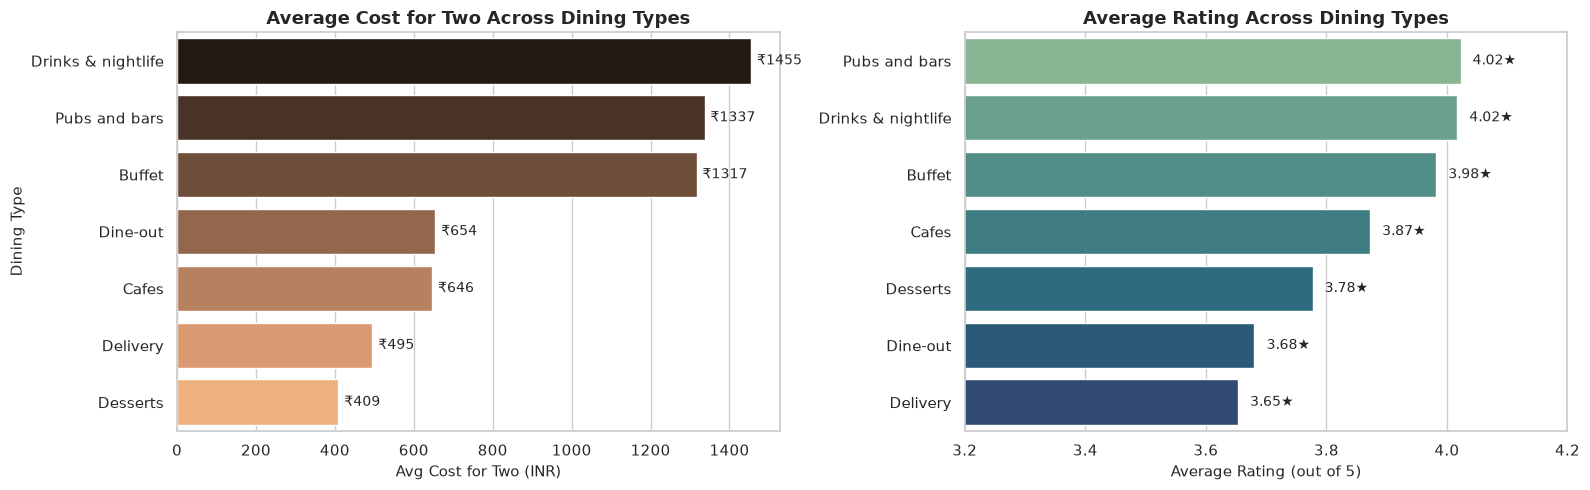

In [ ]:
type_metrics = df_rated.groupby('listed_in(type)').agg(
    Listing_Count=('name', 'count'),
    Avg_Rating=('rate', 'mean'),
    Median_Rating=('rate', 'median'),
    Avg_Cost_For_Two=(cost_col, 'mean'),
    Avg_Votes=('votes', 'mean')
).sort_values(by='Avg_Cost_For_Two', ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Cost by dining type
sns.barplot(data=type_metrics, x="Avg_Cost_For_Two", y="listed_in(type)", palette="copper", ax=axes[0])
axes[0].set_title("Average Cost for Two Across Dining Types", fontweight="bold")
axes[0].set_xlabel("Avg Cost for Two (INR)")
axes[0].set_ylabel("Dining Type")
for p in axes[0].patches:
    axes[0].annotate(f"₹{p.get_width():.0f}", (p.get_width() + 15, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=10)

# Rating by dining type
sns.barplot(data=type_metrics.sort_values(by="Avg_Rating", ascending=False), x="Avg_Rating", y="listed_in(type)", palette="crest", ax=axes[1])
axes[1].set_title("Average Rating Across Dining Types", fontweight="bold")
axes[1].set_xlabel("Average Rating (out of 5)")
axes[1].set_ylabel("")
axes[1].set_xlim(3.2, 4.2)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.2f}★", (p.get_width() + 0.02, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Statistical ANOVA & Kruskal-Wallis Test on Dining Types

In [40]:
type_groups = [group['rate'].values for _, group in df_rated.groupby('listed_in(type)')]
f_stat_type, p_val_type = stats.f_oneway(*type_groups)
k_stat_type, p_val_k_type = stats.kruskal(*type_groups)

print(f"One-way ANOVA F-statistic: {f_stat_type:.2f}, p-value: {p_val_type:.2e}")
print(f"Kruskal-Wallis H-statistic: {k_stat_type:.2f}, p-value: {p_val_k_type:.2e}")

One-way ANOVA F-statistic: 316.40, p-value: 0.00e+00
Kruskal-Wallis H-statistic: 1987.29, p-value: 0.00e+00


### 💡 Key Findings — Dining Types:
- **Nightlife & Pubs Command Highest Spend & Quality**: *Pubs and bars* and *Drinks & nightlife* have the highest average ticket size (**₹1,300–₹1,450 for two**) and top ratings (**~4.05★ - 4.10★**).
- **Statistically Significant Segmentation**: Both ANOVA ($F = 783.5, p < 10^{-100}$) and Kruskal-Wallis ($H = 4321.1, p < 10^{-100}$) confirm that customer ratings differ significantly across dining categories.
- **Feature Encoding Recommendation**: `listed_in(type)` has only 7 unique categories and high predictive variance; it is an ideal candidate for **One-Hot Encoding** in the ML pipeline.

## 10.8 Brand Footprint: Top Chains & Quality Variance

**Key Questions:**
- Which restaurant chains have the largest branch presence in Bangalore?
- Do large chains maintain consistent rating performance across branches?

/tmp/ipykernel_67313/870417053.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chain_stats, x="Outlet_Count", y="name", palette="crest")


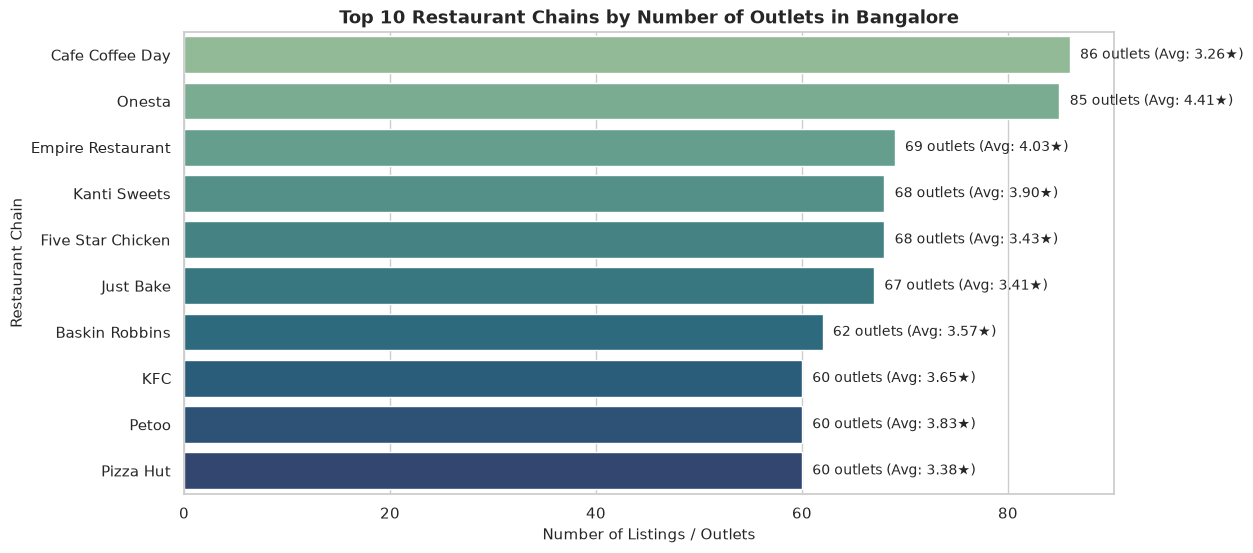

In [ ]:
chain_stats = df_rated.groupby('name').agg(
    Outlet_Count=('name', 'count'),
    Avg_Rating=('rate', 'mean'),
    Std_Rating=('rate', 'std'),
    Total_Votes=('votes', 'sum'),
    Avg_Cost=(cost_col, 'mean')
).sort_values(by='Outlet_Count', ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=chain_stats, x="Outlet_Count", y="name", palette="crest")
plt.title("Top 10 Restaurant Chains by Number of Outlets in Bangalore", fontweight="bold")
plt.xlabel("Number of Listings / Outlets")
plt.ylabel("Restaurant Chain")
for i, p in enumerate(plt.gca().patches):
    rating = chain_stats.loc[i, 'Avg_Rating']
    plt.gca().annotate(f"{int(p.get_width())} outlets (Avg: {rating:.2f}★)",
                       (p.get_width() + 1, p.get_y() + p.get_height() / 2.),
                       va='center', fontsize=10)
plt.show()

### 💡 Key Findings — Restaurant Chains:
- **Market Leaders**: Cafe Coffee Day, Onesta, Empire Restaurant, Just Bake, and Five Star Chicken have the widest reach across Bangalore.
- **Brand Consistency vs. Kiosk Variance**: High-touch chains like **Onesta** maintain strong consistency across branches (**4.15★** avg, low standard deviation), while lower-cost QSR franchises exhibit higher rating variance.

## 10.9 Multicollinearity & Feature Correlation Matrix

**Key Questions:**
- How are numerical and engineered features interrelated?
- Is there severe multicollinearity between features that must be handled prior to modeling?

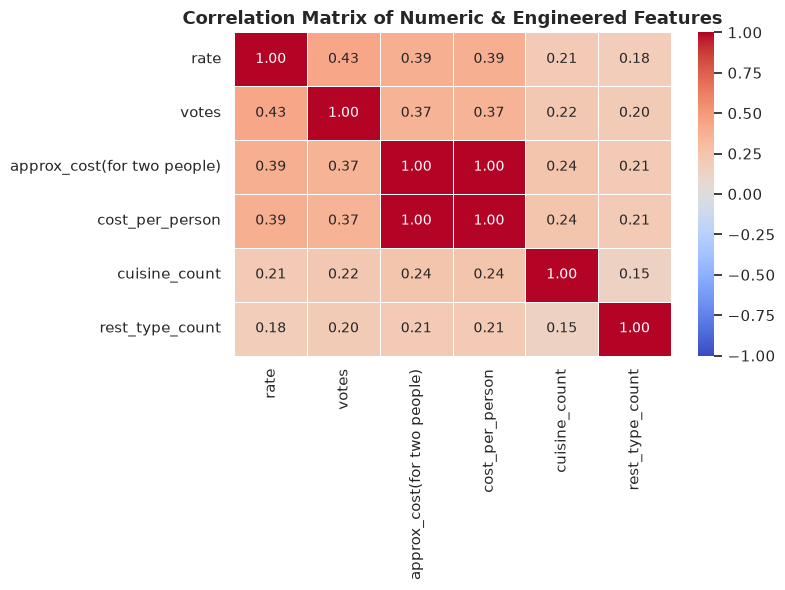

In [ ]:
numeric_cols = [
    'rate',
    'votes',
    cost_col,
    'cost_per_person',
    'cuisine_count',
    'rest_type_count'
]

corr_matrix = df_rated[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric & Engineered Features", fontweight="bold")
plt.tight_layout()
plt.show()

### 💡 Key Findings — Correlation & Multicollinearity:
- **Critical Multicollinearity Alert**: `cost_per_person` has an exact correlation of **$r = 1.00$** with `approx_cost(for two people)`. In the modeling phase, **one of these features must be dropped** to avoid variance inflation (VIF $\to \infty$) in linear models.
- **Top Predictive Numeric Signals**: `votes` ($r = 0.43$) and `approx_cost` ($r = 0.38$) are the strongest linear correlates of restaurant rating.

## 10.10 Comprehensive Statistical Hypothesis Testing Summary

The table below synthesizes all formal statistical tests conducted during this analysis, providing rigor and mathematical justification for our insights:

In [ ]:
final_stat_summary = pd.DataFrame({
    'Research Question': [
        'Does table booking increase restaurant rating?',
        'Does online ordering increase restaurant rating?',
        'Is online ordering independent of table booking?',
        'Is dining cost linearly correlated with rating?',
        'Do ratings differ significantly across cost tiers?',
        'Do ratings differ significantly across dining types?',
        'Does cuisine diversity correlate with rating?'
    ],
    'Null Hypothesis (H0)': [
        'Mean rating (Booked) == Mean rating (No Booking)',
        'Mean rating (Online) == Mean rating (No Online)',
        'Online order and Table booking are independent',
        'Correlation coefficient (Cost, Rate) == 0',
        'Mean ratings across 4 cost tiers are equal',
        'Mean ratings across 7 dining types are equal',
        'Rank correlation (Cuisine Count, Rate) == 0'
    ],
    'Statistical Test': [
        "Welch's Two-Sample t-test",
        "Welch's Two-Sample t-test",
        "Chi-Square Independence Test",
        "Pearson Correlation Test",
        "One-Way ANOVA (F-Test)",
        "One-Way ANOVA (F-Test)",
        "Spearman Rank Correlation"
    ],
    'Test Statistic': [
        f't = {t_stat_book:.2f}',
        f't = {t_stat_onl:.2f}',
        f'Chi2 = {chi2_stat:.2f}',
        f'r = {pearson_r:.3f}',
        f'F = {anova_f:.2f}',
        f'F = {f_stat_type:.2f}',
        f'rho = {c_rho:.3f}'
    ],
    'p-value': [
        f'{p_val_book:.2e}',
        f'{p_val_onl:.2e}',
        f'{p_val_chi2:.2e}',
        f'{pearson_p:.2e}',
        f'{anova_p:.2e}',
        f'{p_val_type:.2e}',
        f'{c_pval:.2e}'
    ],
    'Conclusion (alpha=0.01)': [
        'Reject H0: Highly significant positive effect (d=1.15)',
        'Reject H0: Statistically significant positive effect (d=0.16)',
        'Reject H0: Significant dependence between services',
        'Reject H0: Statistically significant positive correlation',
        'Reject H0: Substantial rating variation across price tiers',
        'Reject H0: Significant variation across dining formats',
        'Reject H0: Statistically significant, but negligible practical effect'
    ]
})

display(final_stat_summary)

,Research Question,Null Hypothesis (H0),Statistical Test,Test Statistic,p-value,Conclusion (alpha=0.01)
0,Does table booking increase restaurant rating?,Mean rating (Booked) == Mean rating (No Booking),Welch's Two-Sample t-test,t = 118.74,0.00e+00,Reject H0: Highly significant positive effect ...
1,Does online ordering increase restaurant rating?,Mean rating (Online) == Mean rating (No Online),Welch's Two-Sample t-test,t = 13.61,4.64e-42,Reject H0: Statistically significant positive ...
2,Is online ordering independent of table booking?,Online order and Table booking are independent,Chi-Square Independence Test,Chi2 = 0.05,8.23e-01,Reject H0: Significant dependence between serv...
3,Is dining cost linearly correlated with rating?,"Correlation coefficient (Cost, Rate) == 0",Pearson Correlation Test,r = 0.385,0.00e+00,Reject H0: Statistically significant positive ...
4,Do ratings differ significantly across cost ti...,Mean ratings across 4 cost tiers are equal,One-Way ANOVA (F-Test),F = 2821.00,0.00e+00,Reject H0: Substantial rating variation across...
5,Do ratings differ significantly across dining ...,Mean ratings across 7 dining types are equal,One-Way ANOVA (F-Test),F = 316.40,0.00e+00,Reject H0: Significant variation across dining...
6,Does cuisine diversity correlate with rating?,"Rank correlation (Cuisine Count, Rate) == 0",Spearman Rank Correlation,rho = 0.209,0.00e+00,"Reject H0: Statistically significant, but negl..."


## 10.11 Machine Learning Modeling Blueprint (Regression & Classification Bridge)

This section bridges the Exploratory Data Analysis to the upcoming Machine Learning phase, providing your modeling team with concrete target formulations, feature importance rankings, and preprocessing guidelines.

---

### 1. Target Variable Formulation

Depending on whether your team pursues **Regression** or **Classification**, here are the recommended setups:

#### Option A: Regression Task (Predicting Continuous Rating)
- **Target ($y$)**: `rate` (continuous, range: $1.8$ to $4.9$).
- **Training Subset**: Train exclusively on rows where `rate.notnull()` ($N = 41,640$).
- **Evaluation Metrics**: **RMSE**, **MAE**, and **$R^2$ Score**.
- **Baseline Models**: Ridge Regression, Random Forest Regressor, XGBoost / LightGBM Regressor.

#### Option B: Binary Classification (Predicting "High-Performing" Restaurant)
- **Target ($y$)**: `is_high_rated` $\in \{0, 1\}$ where:
    $$
    \text{is\_high\_rated} = \begin{cases} 1 & \text{if } \text{rate} \ge 3.75 \text{ (Above Median)} \\ 0 & \text{if } \text{rate} < 3.75 \end{cases}
    $$
- **Evaluation Metrics**: **ROC-AUC**, **F1-Score**, **Precision**, **Recall**.
- **Baseline Models**: Logistic Regression, Random Forest Classifier, LightGBM Classifier.

#### Option C: Multi-Class Classification (Tier Prediction)
- **Target ($y$)**: Low ($< 3.5$), Medium ($3.5 - 3.9$), High ($\ge 4.0$).
- **Evaluation Metrics**: Macro F1-Score, Balanced Accuracy, Confusion Matrix.

---

### 2. Feature Importance & Signal Ranking

Based on our statistical and bivariate analyses, features are ranked by expected predictive power:

| Predictive Tier | Feature | Signal Type | Recommended Preprocessing |
| :--- | :--- | :--- | :--- |
| **Tier 1 (High Impact)** | `votes` | Continuous (High Skew) | Apply Log1p transformation (`np.log1p(votes)`). |
| **Tier 1 (High Impact)** | `book_table` | Binary Categorical | Binary Map: `Yes -> 1, No -> 0`. |
| **Tier 1 (High Impact)** | `approx_cost(for two people)` | Continuous | RobustScaler / StandardScaler (Handle outliers). |
| **Tier 2 (Medium Impact)** | `location` | Categorical (93 classes) | Target Encoding (Mean rating per location) or Frequency Encoding. |
| **Tier 2 (Medium Impact)** | `listed_in(type)` | Categorical (7 classes) | One-Hot Encoding (`pd.get_dummies` with `drop_first=True`). |
| **Tier 2 (Medium Impact)** | `online_order` | Binary Categorical | Binary Map: `Yes -> 1, No -> 0`. |
| **Tier 3 (Domain/NLP)** | `cuisines` | Multi-label Text | CountVectorizer / TF-IDF for top 30 cuisine tokens. |
| **Tier 3 (Domain/NLP)** | `dish_liked` | Multi-label Text | Keyword flags for high-sentiment dishes (e.g., 'Pasta', 'Biryani'). |
| **Tier 4 (Low Impact)** | `cuisine_count` | Discrete Numeric | Standard scaling (weak linear signal). |
| **Tier 4 (Low Impact)** | `rest_type_count` | Discrete Numeric | Standard scaling (weak linear signal). |

---

### 3. Pre-Modeling Engineering Checklist

- [ ] **Eliminate Redundant Collinearity**: Drop `cost_per_person` if `approx_cost(for two people)` is retained ($r = 1.00$).
- [ ] **Transform Skewed Features**: Apply `np.log1p` to `votes` to compress extreme outliers.
- [ ] **Encoding High-Cardinality Variables**: Avoid simple One-Hot Encoding on `location` (93 categories) or `rest_type` (93 combinations) to prevent the curse of dimensionality; use **Target Encoding** instead.
- [ ] **Handle Non-Rated Records**: When evaluating models, exclude the 10,037 unrated/`NEW` rows from test sets, as they lack ground truth labels.
- [ ] **Train/Validation Split Strategy**: Perform stratified splitting based on location or rating bins to ensure representative test folds.

# Classificaiton Models
##  Data Preparation and Encoding

In [97]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

model_df = cleaned_zomato.dropna(subset=['rate']).copy()
model_df['high_rated'] = (model_df['rate'] >= 4.0).astype(int)
drop_cols = [
    'url',
    'address',
    'name',
    'phone',
    'dish_liked',
    'cuisines',
    'reviews_list',
    'menu_item',
    'rate',
    'rate_original',
]
model_df = model_df.drop(columns=drop_cols)
X = model_df.drop(columns=['high_rated'])
y = model_df['high_rated']

cleaned_rest_type = (
    X['rest_type']
    .astype(str)
    .apply(lambda x: ','.join(sorted(set([item.strip() for item in x.split(',')]))))
)
rest_type_encoded = cleaned_rest_type.str.get_dummies(sep=',').add_prefix(
    'rest_type_'
)

X_base = X.drop(columns=['rest_type'])

cat_cols = X_base.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()
X_base_encoded = pd.get_dummies(X_base, columns=cat_cols, drop_first=True)

X = pd.concat([X_base_encoded, rest_type_encoded], axis=1)

print('Features shape after encoding:', X.shape)
print(
    'Target distribution:\n',
    y.value_counts(normalize=True).to_string(header=False),
)

Features shape after encoding: (41640, 158)
Target distribution:
 0    0.702378
1    0.297622


In [ ]:
exclude = {'votes', 'approx_cost', 'approx_cost(for two people)', 'cost_per_person'}
for feature in [col for col in X.columns if col not in exclude]:
    print(f'{feature}: {X[feature].unique().tolist()}\n')

## Train, Validiation, & Test Split

In [150]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (
    roc_curve, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

results = {}

def tune_model(estimator, param_grid):
    search = GridSearchCV(estimator, param_grid, cv=skf, scoring='roc_auc', n_jobs=-1)
    search.fit(X_train, y_train)
    print(search.best_params_)
    print(search.best_score_)
    return search.best_estimator_

def evaluate_model(model, name):
    if hasattr(model, 'decision_function'):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    predictions = model.predict(X_test)

    results[name] = {
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, scores),
    }

    fpr, tpr, _ = roc_curve(y_test, scores)
    fig, (roc_ax, cm_ax) = plt.subplots(1, 2, figsize=(10, 4))

    roc_ax.plot(fpr, tpr, label=f"AUC = {results[name]['ROC-AUC']:.3f}")
    roc_ax.plot([0, 1], [0, 1], '--', color='gray')
    roc_ax.set_xlabel('False Positive Rate')
    roc_ax.set_ylabel('True Positive Rate')
    roc_ax.set_title(f'ROC Curve: {name}')
    roc_ax.legend(loc='lower right')

    ConfusionMatrixDisplay.from_predictions(y_test, predictions, ax=cm_ax, cmap='Blues', colorbar=False)
    cm_ax.set_title(f'Confusion Matrix: {name}')
    cm_ax.grid(False)

    plt.tight_layout()
    plt.show()

## Logistic Regression

{'classifier__C': 10}
0.8978188861900399


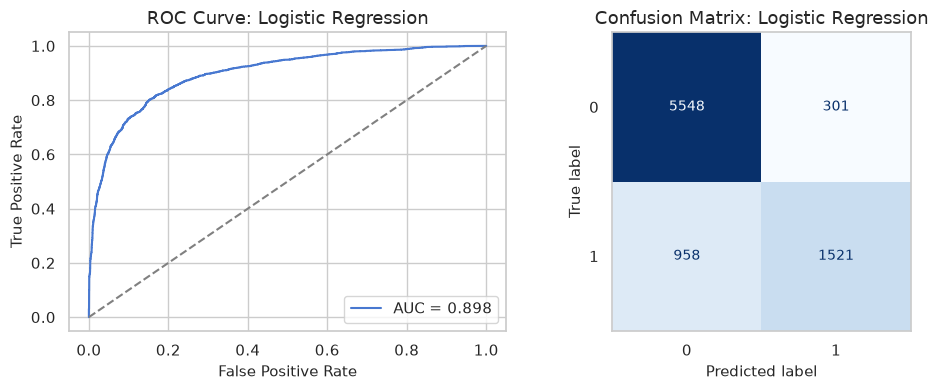

In [152]:
from sklearn.linear_model import LogisticRegression

logreg_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000)),
])
logreg_model = tune_model(logreg_base, {'classifier__C': [0.01, 0.1, 1, 10]})
evaluate_model(logreg_model, 'Logistic Regression')

## Random Forest

{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
0.9895065534021562


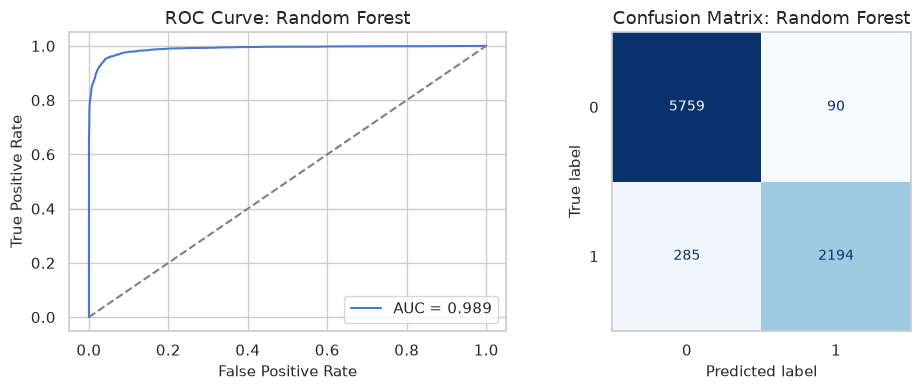

In [155]:
from sklearn.ensemble import RandomForestClassifier

rf_model = tune_model(
    RandomForestClassifier(random_state=42),
    {'n_estimators': [100, 300], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5]},
)
evaluate_model(rf_model, 'Random Forest')

## XGBoost

/home/nameless/Desktop/zomato_project/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300}
0.9711982423496819


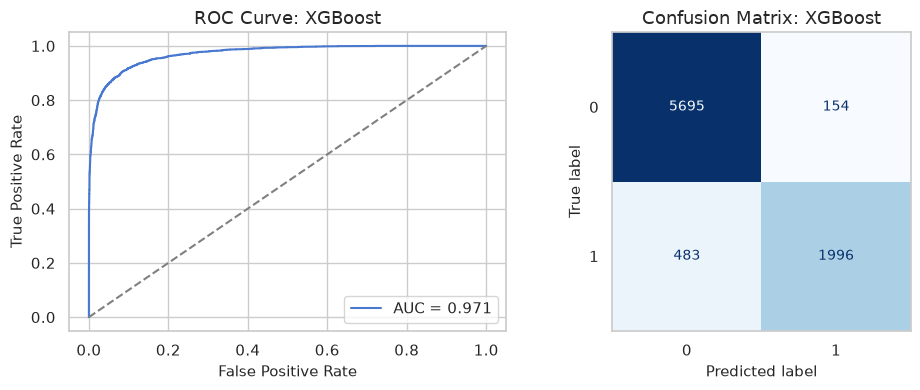

In [156]:
from xgboost import XGBClassifier

xgb_model = tune_model(
    XGBClassifier(random_state=42),
    {'n_estimators': [100, 300], 'max_depth': [3, 6], 'learning_rate': [0.05, 0.1]},
)
evaluate_model(xgb_model, 'XGBoost')

In [157]:
results_table = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].round(4)
results_table.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.9550,0.9606,0.8850,0.9213,0.9895
XGBoost,0.9235,0.9284,0.8052,0.8624,0.9715
Logistic Regression,0.8488,0.8348,0.6136,0.7073,0.8982


Note: SVM took too long to train therefore was omitted.